# 04 — Evaluation: 90-day horizon backtesting

Notebook [`03_modeling.ipynb`](03_modeling.ipynb) scored models **1 day ahead** — useful for comparing learners, but not how demand forecasting is deployed. A supply chain orders stock **months** in advance: on the forecast date, the most recent actual sales are ~3 months old.

This notebook closes that gap:

1. **Horizon-safe features** — every feature is computable 91 days before the target date: calendar variables, lags ≥ 91 days, and rolling statistics ending 91 days back. No information from the forecast window leaks in.
2. **Rolling-origin backtest** — instead of one lucky (or unlucky) test window, we forecast **each quarter of 2017** using only data available a quarter earlier, and report the spread of scores.
3. **A horizon-appropriate baseline** — `sales_lag_364`: same weekday, one year earlier (364 = 52 whole weeks, so weekday alignment is preserved; a 365-day lag would compare Mondays to Sundays).

- **Input:** `data/raw/train.csv` (features are rebuilt here with the 91-day shift)
- **Outputs:** metrics → `outputs/metrics/`, predictions → `outputs/forecasts/`, figures → `outputs/figures/`

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

from src.data.load import load_raw
from src.features.build_features import build_features
from src.evaluation.metrics import smape
from src.models.train import train_lgbm

PALETTE = ["#2a78d6", "#008300", "#e87ba4", "#eda100", "#1baf7a", "#eb6834", "#4a3aa7", "#e34948"]
BLUE, GREEN = PALETTE[0], PALETTE[1]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "figure.dpi": 110, "font.size": 11,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

FIG_DIR = Path("../outputs/figures")
METRICS_DIR = Path("../outputs/metrics")
FORECASTS_DIR = Path("../outputs/forecasts")

## 1. Horizon-safe feature set

`HORIZON = 91` days. Every history-based feature is shifted by at least 91 days, so each row is predicted as if it were exactly one quarter away — the hardest case within the window a real order would cover.

Features come from [`src/features/build_features.py`](../src/features/build_features.py) — the same code path covered by the unit tests, including [an anti-leakage test](../tests/test_features.py) that verifies no feature can see sales data closer than `horizon` days to the target. The function itself refuses lags shorter than the horizon. Lags 91/98 are weekday-aligned recent history; 364 is the weekday-aligned yearly lag.

In [2]:
HORIZON = 91

df = load_raw("../data/raw/train.csv")
df = build_features(df, lags=(91, 98, 182, 364, 365), windows=(28, 91), horizon=HORIZON)

df["store"] = df["store"].astype("category")
df["item"] = df["item"].astype("category")

FEATURES = [c for c in df.columns if c not in ("date", "sales")]
print(f"{len(df):,} rows | {len(FEATURES)} horizon-safe features")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")

730,500 rows | 20 horizon-safe features
Date range: 2014-01-01 to 2017-12-31


## 2. Rolling-origin backtest

Four folds, one per quarter of 2017. For each fold the model trains only on data **before** the quarter (with the last 91 days held out for early stopping) and forecasts the full quarter — 46,000 predictions per fold, 500 series each day.

In [3]:
FOLDS = [
    ("2017-Q1", "2017-01-01", "2017-04-01"),
    ("2017-Q2", "2017-04-01", "2017-07-01"),
    ("2017-Q3", "2017-07-01", "2017-10-01"),
    ("2017-Q4", "2017-10-01", "2018-01-01"),
]

fold_rows, all_preds = [], []

for name, start, end in FOLDS:
    test = df[(df["date"] >= start) & (df["date"] < end)]
    known = df[df["date"] < start]
    es_cut = pd.Timestamp(start) - pd.Timedelta(days=91)
    fit = known[known["date"] < es_cut]
    es = known[known["date"] >= es_cut]

    model = train_lgbm(fit[FEATURES], fit["sales"], es[FEATURES], es["sales"])

    pred_lgbm = model.predict(test[FEATURES], num_iteration=model.best_iteration_)
    pred_naive = test["sales_lag_364"].to_numpy()
    y = test["sales"].to_numpy()

    fold_rows.append({"fold": name,
                      "SMAPE naive": smape(y, pred_naive),
                      "SMAPE LightGBM": smape(y, pred_lgbm),
                      "MAE naive": np.mean(np.abs(y - pred_naive)),
                      "MAE LightGBM": np.mean(np.abs(y - pred_lgbm))})

    p = test[["date", "store", "item", "sales"]].copy()
    p["fold"], p["pred_naive"], p["pred_lgbm"] = name, pred_naive, pred_lgbm
    all_preds.append(p)
    print(f"{name}: naive SMAPE {fold_rows[-1]['SMAPE naive']:.2f} | "
          f"LightGBM SMAPE {fold_rows[-1]['SMAPE LightGBM']:.2f} "
          f"(best_iter {model.best_iteration_})")

folds_df = pd.DataFrame(fold_rows)
preds = pd.concat(all_preds, ignore_index=True)
folds_df.round(2)

2017-Q1: naive SMAPE 19.15 | LightGBM SMAPE 13.52 (best_iter 1500)


2017-Q2: naive SMAPE 15.87 | LightGBM SMAPE 11.12 (best_iter 1500)


2017-Q3: naive SMAPE 15.74 | LightGBM SMAPE 11.22 (best_iter 1064)


2017-Q4: naive SMAPE 17.86 | LightGBM SMAPE 12.42 (best_iter 1500)


,fold,SMAPE naive,SMAPE LightGBM,MAE naive,MAE LightGBM
0,2017-Q1,19.15,13.52,7.52,5.37
1,2017-Q2,15.87,11.12,9.09,6.47
2,2017-Q3,15.74,11.22,9.23,6.71
3,2017-Q4,17.86,12.42,8.35,5.91


## 3. Scores across folds

The spread across quarters is the point of a rolling-origin backtest: a single window can flatter or punish a model depending on the season it happens to cover.

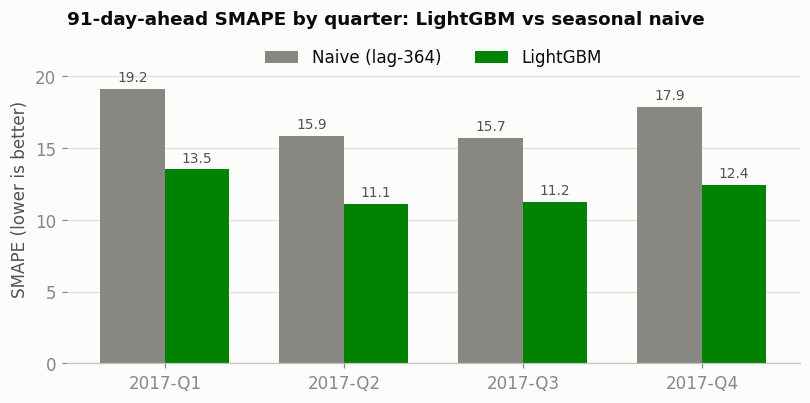

Mean SMAPE — naive: 17.15 | LightGBM: 12.07 (30% better)


In [4]:
x = np.arange(len(folds_df))
width = 0.36

fig, ax = plt.subplots(figsize=(7.5, 3.8))
b1 = ax.bar(x - width / 2, folds_df["SMAPE naive"], width,
            color=MUTED, label="Naive (lag-364)")
b2 = ax.bar(x + width / 2, folds_df["SMAPE LightGBM"], width,
            color=GREEN, label="LightGBM")
ax.bar_label(b1, fmt="%.1f", padding=3, color=INK2, fontsize=9)
ax.bar_label(b2, fmt="%.1f", padding=3, color=INK2, fontsize=9)
ax.set_xticks(x, folds_df["fold"])
ax.set_ylabel("SMAPE (lower is better)")
ax.set_title("91-day-ahead SMAPE by quarter: LightGBM vs seasonal naive")
ax.set_ylim(0, 23)
ax.legend(frameon=False, loc="upper center", ncols=2)
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "eval_01_smape_by_fold.png", dpi=150, bbox_inches="tight")
plt.show()

mean_naive = folds_df["SMAPE naive"].mean()
mean_lgbm = folds_df["SMAPE LightGBM"].mean()
print(f"Mean SMAPE — naive: {mean_naive:.2f} | LightGBM: {mean_lgbm:.2f} "
      f"({(1 - mean_lgbm / mean_naive) * 100:.0f}% better)")

## 4. What a quarter-ahead forecast looks like

Total daily demand in Q4 2017, forecast 91 days in advance. The model has no access to any sales after 2017-09-30 — the weekly sawtooth and the December dip must come entirely from calendar features and year-old history.

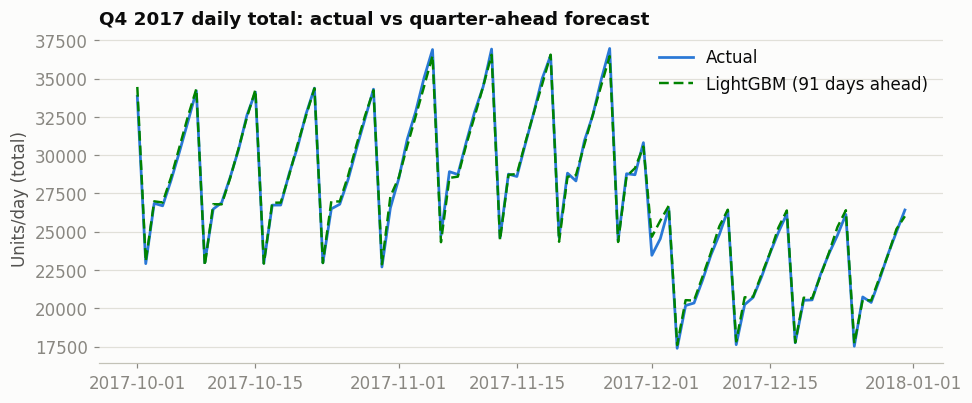

In [5]:
q4 = preds[preds["fold"] == "2017-Q4"].groupby("date")[["sales", "pred_lgbm"]].sum()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(q4.index, q4["sales"], color=BLUE, linewidth=1.8, label="Actual")
ax.plot(q4.index, q4["pred_lgbm"], color=GREEN, linewidth=1.6,
        linestyle=(0, (4, 2)), label="LightGBM (91 days ahead)")
ax.set_title("Q4 2017 daily total: actual vs quarter-ahead forecast")
ax.set_ylabel("Units/day (total)")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "eval_02_q4_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Persist results

In [6]:
folds_df.round(3).to_csv(METRICS_DIR / "backtest_metrics.csv", index=False)
preds.to_parquet(FORECASTS_DIR / "backtest_predictions.parquet", index=False)
print("Saved backtest_metrics.csv and backtest_predictions.parquet")
folds_df.round(2)

Saved backtest_metrics.csv and backtest_predictions.parquet


,fold,SMAPE naive,SMAPE LightGBM,MAE naive,MAE LightGBM
0,2017-Q1,19.15,13.52,7.52,5.37
1,2017-Q2,15.87,11.12,9.09,6.47
2,2017-Q3,15.74,11.22,9.23,6.71
3,2017-Q4,17.86,12.42,8.35,5.91


## Summary

| Fold | SMAPE naive (lag-364) | SMAPE LightGBM |
|---|---|---|
| 2017-Q1 | 19.15 | 13.52 |
| 2017-Q2 | 15.87 | 11.12 |
| 2017-Q3 | 15.74 | 11.22 |
| 2017-Q4 | 17.86 | 12.42 |
| **Mean** | **17.15** | **12.07** |

- **LightGBM beats the seasonal naive by ~30% at a full quarter of lead time**, consistently across all four folds — the gap is not an artifact of one lucky window.
- **The 91-day-ahead SMAPE (12.07) is essentially as good as the 1-day-ahead score from notebook 03 (12.44).** That is a property of this dataset, not magic: demand here is dominated by stable weekly/yearly seasonality and a slow trend, all of which survive a 91-day shift. Volatile, promotion-driven demand would degrade far more with horizon.
- **Q1 is the hardest quarter** for both models — the post-holiday demand dip depends on year-old history and year-boundary calendar effects.
- For reference, top solutions of the original Kaggle challenge score ~12.5 SMAPE on its 3-month test window.

**Caveats & next steps:** per-row 91-day shift is a uniform-horizon evaluation — a production system forecasting days 1-90 from a single origin would score slightly better on the near days. Obvious extensions: holiday calendars, per-horizon models, quantile forecasts for safety stock, and promoting the notebook logic into `src/` modules with tests.